<a href="https://colab.research.google.com/github/ravikiranmannepuri/Collab/blob/main/Weather%20prediction%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# install if needed
!pip install seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier





In [5]:
# Load dataset
df = pd.read_csv('/content/seattle-weather.csv')

# show basic info
print(df.head())
print(df.info())
print(df.isnull().sum())


         date  precipitation  temp_max  temp_min  wind  weather
0  2012-01-01            0.0      12.8       5.0   4.7  drizzle
1  2012-01-02           10.9      10.6       2.8   4.5     rain
2  2012-01-03            0.8      11.7       7.2   2.3     rain
3  2012-01-04           20.3      12.2       5.6   4.7     rain
4  2012-01-05            1.3       8.9       2.8   6.1     rain
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB
None
date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weath

In [10]:
# convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# encode target labels ("weather" column)
le = LabelEncoder()
df['weather_encoded'] = le.fit_transform(df['weather'])

# Separate features and target
X = df[['precipitation', 'temp_max', 'temp_min', 'wind']]
y = df['weather_encoded']

# scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)


In [12]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

Accuracy: 0.8191126279863481

Classification Report:
               precision    recall  f1-score   support

           0       0.20      0.11      0.14         9
           1       0.50      0.12      0.19        25
           2       0.93      0.92      0.92       120
           3       0.40      0.25      0.31         8
           4       0.78      0.95      0.86       131

    accuracy                           0.82       293
   macro avg       0.56      0.47      0.48       293
weighted avg       0.79      0.82      0.79       293



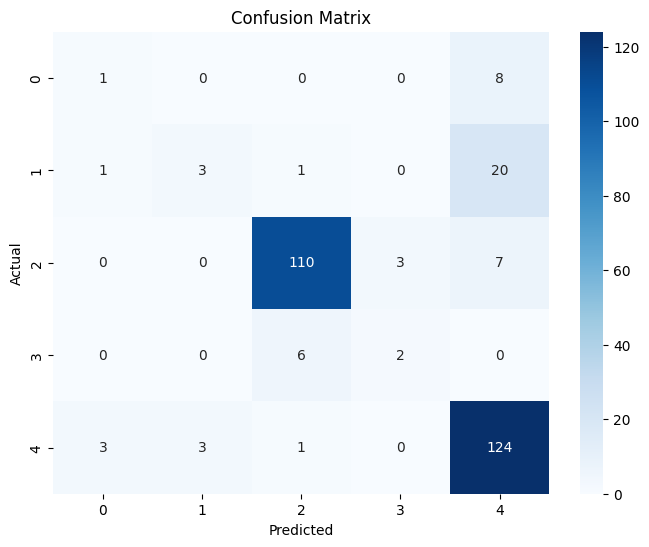

In [14]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


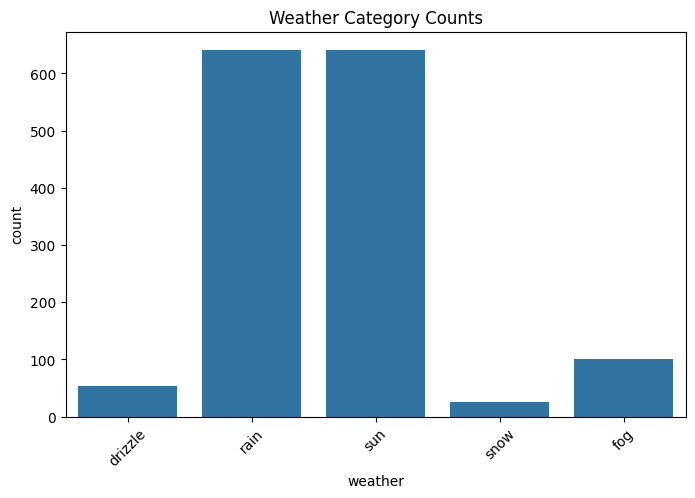

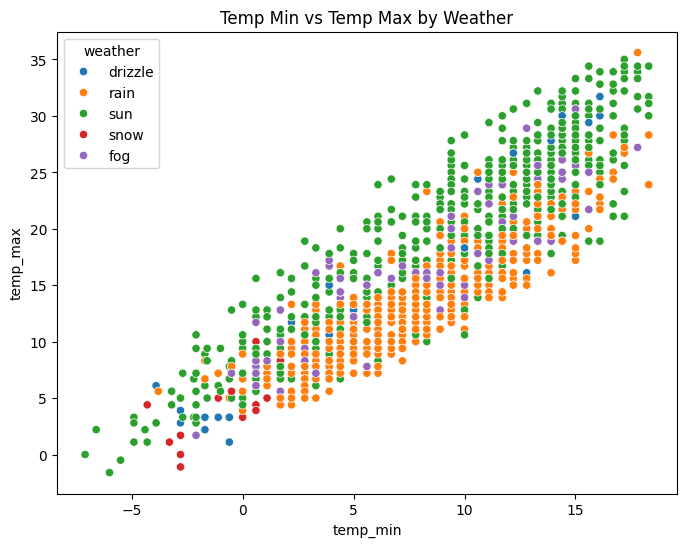

In [16]:
# distribution of weather categories
plt.figure(figsize=(8,5))
sns.countplot(x='weather', data=df)
plt.title("Weather Category Counts")
plt.xticks(rotation=45)
plt.show()

# scatter plot of temp_min vs temp_max colored by weather
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='temp_min', y='temp_max', hue='weather')
plt.title("Temp Min vs Temp Max by Weather")
plt.show()


In [18]:
import joblib
joblib.dump(model, 'weather_model.pkl')

# later, to load
model_loaded = joblib.load('weather_model.pkl')


In [23]:
new_data = [[0.1, 60.2, 50.1, 5.2]]  # example
new_data_scaled = scaler.transform(new_data)
pred_encoded = model_loaded.predict(new_data_scaled)
print("Predicted weather:", le.inverse_transform(pred_encoded))


Predicted weather: ['sun']


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
